<a href="https://colab.research.google.com/github/pakapornsup-cloud/Data-Warehouse-and-Data-Mining/blob/main/%E0%B9%81%E0%B8%9A%E0%B8%9A%E0%B8%9D%E0%B8%B6%E0%B8%81%E0%B8%AB%E0%B8%B1%E0%B8%94_IQR_Anomaly_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# แบบฝึกหัด IQR : Anomaly Detection

IQR = Q3 − Q1 · รั้วล่าง = Q1 − k·IQR · รั้วบน = Q3 + k·IQR · k = 1.5 (outlier) หรือ 3 (extreme outlier)


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## ข้อ 1 · คำนวณ IQR และรั้ว (20 คะแนน)

ปริมาณน้ำที่บ้านหลังหนึ่งใช้ต่อวัน 15 วัน

1. ใช้ `np.percentile` หา Q1, Q3, IQR และรั้วล่าง/รั้วบน (k = 1.5)
2. แสดงค่าที่อยู่นอกรั้ว

In [3]:
import numpy as np

water = np.array([182, 175, 190, 168, 185, 178, 420, 181, 172, 188, 176, 95, 183, 179, 186], float)  # ลิตร/วัน 15 วัน

# TODO 1.1–1.2

Q1 = np.percentile(water, 25)
Q3 = np.percentile(water, 75)
IQR = Q3 - Q1

lo = Q1 - 1.5 * IQR
hi = Q3 + 1.5 * IQR

outliers = water[(water < lo)  |  (water > hi)]

print(f"Q1 = {Q1}")
print(f"Q3 = {Q3}")
print(f"IQR = {IQR}")
print(f"รั้วล่าง = {lo}")
print(f"รั้วบน = {hi}")
print("Outliers =", outliers)

Q1 = 175.5
Q3 = 185.5
IQR = 10.0
รั้วล่าง = 160.5
รั้วบน = 200.5
Outliers = [420.  95.]


## ข้อ 2 · เขียนฟังก์ชัน `iqr_outliers` (20 คะแนน)

1. เขียนฟังก์ชันรับ `x` และ `k=1.5` คืนค่า `(mask, lo, hi)` โดย `mask` เป็น boolean array ว่าค่าใดอยู่นอกรั้ว
2. ใช้กับยอดขาย 18 วัน ที่ k = 1.5 และ k = 3 · ค่าใดเป็น outlier ทั่วไป ค่าใดเป็น extreme outlier
3. ทดสอบด้วย `assert` อย่างน้อย 2 กรณี เช่น ข้อมูลไม่มี outlier ต้องได้ mask เป็น False ทั้งหมด

In [9]:
def iqr_outliers(x, k=1.5):
    # TODO
    Q1 = np.percentile(x, 25)
    Q3 = np.percentile(x, 75)
    IQR = Q3 - Q1

    lo = Q1 - k * IQR
    hi = Q3 + k * IQR

    mask = (x < lo) | (x > hi)
    return mask, lo, hi

sales = np.array([52, 48, 55, 61, 47, 50, 53, 49, 58, 51, 120, 54, 46, 79, 50, 57, 30, 52], float)  # ยอดขาย (พันบาท) 18 วัน

# TODO 2.2
mask15,lo15,hi15 = iqr_outliers(sales, k=1.5)
mask3,lo3,hi3 = iqr_outliers(sales, k=3)

print("k=1.5")
print("รั่วล่าง =", lo15)
print("รั้วบน =", hi15)
print("Outliers =", sales[mask15])

print("k3")
print("รั่วล่าง =", lo3)
print("รั้วบน =", hi3)
print("Extreme Outliers  =", sales[mask3])

# TODO 2.3 assert

test1 = np.array([10,11,12,13,100], float)
m1, _,_ = iqr_outliers(test1)
assert np.any(m1)

test2 = np.array([10,11,12,13], float)
m2, _,_ = iqr_outliers(test2)
assert np.all(m2==False)
print("All tests passed!!!")

k=1.5
รั่วล่าง = 38.375
รั้วบน = 67.375
Outliers = [120.  79.  30.]
k3
รั่วล่าง = 27.5
รั้วบน = 78.25
Extreme Outliers  = [120.  79.]
All tests passed!!!


## ข้อ 3 · Boxplot กับรั้ว IQR (20 คะแนน)

1. วาด boxplot ของ `sales` ด้วย `plt.boxplot(sales, whis=1.5)` แล้วเก็บผลที่ return ไว้ในตัวแปร
2. วาดเส้นแนวนอนที่รั้วล่างและรั้วบนจากข้อ 2 ทับลงบนกราฟ
3. ดึงค่าปลายหนวด (`['whiskers']`) และจุด flier (`['fliers']`) ออกมา เทียบกับผลของ `iqr_outliers`

**คำถาม:** ปลายหนวดอยู่ที่รั้วพอดีหรือไม่ ถ้าไม่ อยู่ที่ไหน

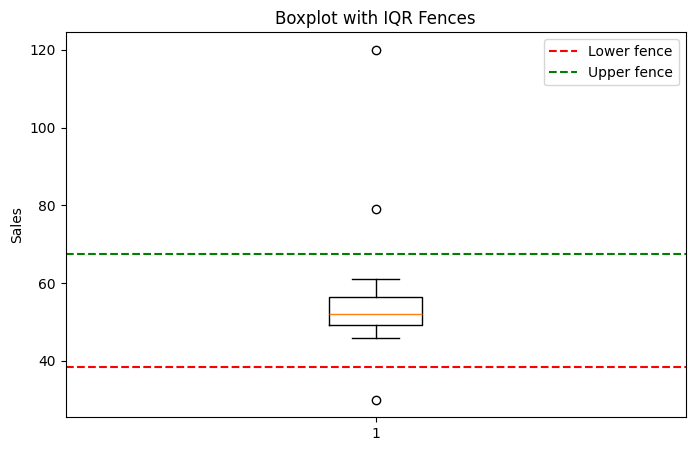

whiskers (ปลายหนวด) = [np.float64(46.0), np.float64(61.0)]
fliers (Outliers จากกราฟ) = [array([ 30., 120.,  79.])]
IQR fences = 38.375 67.375


In [13]:
# TODO ข้อ 3
import matplotlib.pyplot as plt
import numpy as np

fig, ax= plt.subplots(figsize=(8,5))

bp = ax.boxplot(sales, whis=1.5)

#คำนวน
Q1 = np.percentile(sales, 25)
Q3 = np.percentile(sales, 75)
IQR = Q3 - Q1

lo = Q1 - 1.5 * IQR
hi = Q3 + 1.5 * IQR

#วาดเส้น
ax.axhline(lo, color='red', linestyle='--', label='Lower fence')
ax.axhline(hi, color='green', linestyle='--', label='Upper fence')

ax.set_title("Boxplot with IQR Fences")
ax.set_ylabel("Sales")
ax.legend()

plt.show()

#ดึงค่า
whiskers_val = [whisker.get_ydata()[1] for whisker in bp['whiskers']]


# ดึงข้อมูลค่า Y ของ outlier ทั้งหมด
fliers_val = [flier.get_ydata() for flier in bp['fliers']]

print("whiskers (ปลายหนวด) =", whiskers_val)
print("fliers (Outliers จากกราฟ) =", fliers_val)
print("IQR fences =", lo, hi)

## ข้อ 4 · IQR รายกลุ่ม (contextual anomaly) (20 คะแนน)

ค่าจ้างรายเดือน (พันบาท) ของพนักงาน 3 อาชีพ อาชีพละ 8 คน

1. ใช้ `iqr_outliers` กับค่าจ้างทั้ง 24 คนรวมกัน พบ outlier กี่คน
2. ใช้ `groupby('occupation')` คำนวณ IQR แยกแต่ละอาชีพ (ใช้ `.transform` ได้) พบ outlier คนใด
3. ทำตาราง Q1, Q3, IQR, รั้วล่าง, รั้วบน ของแต่ละอาชีพ
4. อธิบายว่าทำไมผลรวมกับผลรายกลุ่มต่างกัน

In [15]:
import pandas as pd

wage = pd.DataFrame({
    'occupation': ['cleaner']*8 + ['clerk']*8 + ['engineer']*8,
    'wage_k': [12,13,12,14,13,12,15,35,  18,20,19,22,21,20,23,9,  60,65,58,70,62,66,64,61]})

# TODO 4.1
def iqr_outliers(x):
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    return x[(x < q1-1.5*iqr) | (x > q3+1.5*iqr)]

print(iqr_outliers(wage['wage_k']))

# TODO 4.2
g = wage.groupby('occupation')['wage_k']
q1 = g.transform(lambda x: x.quantile(0.25))
q3 = g.transform(lambda x: x.quantile(0.75))
iqr = q3 - q1

wage['outlier'] = (wage['wage_k'] < q1-1.5*iqr) | (wage['wage_k'] > q3+1.5*iqr)

print(wage[wage['outlier']])

# TODO 4.3
wage['Q1'] = q1
wage['Q3'] = q3
wage['IQR'] = iqr
wage['lower'] = q1 - 1.5*iqr
wage['upper'] = q3 + 1.5*iqr

print(wage.groupby('occupation')[['Q1','Q3','IQR','lower','upper']].first())

Series([], Name: wage_k, dtype: int64)
   occupation  wage_k  outlier
7     cleaner      35     True
15      clerk       9     True
               Q1     Q3   IQR   lower   upper
occupation                                    
cleaner     12.00  14.25  2.25   8.625  17.625
clerk       18.75  21.25  2.50  15.000  25.000
engineer    60.75  65.25  4.50  54.000  72.000


ผลรวมกับผลรายกลุ่มต่างกัน เพราะ Global IQR นำเงินเดือนของทั้ง 3 อาชีพมาคำนวณรวมกัน ทำให้ช่วง IQR กว้างขึ้น จึงไม่พบ Outlier

แต่ Contextual IQR คำนวณแยกตามอาชีพ ทำให้เห็นความผิดปกติภายในกลุ่มเดียวกัน จึงพบ Outlier 2 คน คือ Cleaner เงินเดือน 35 และ Clerk เงินเดือน 9